# **READ BEFORE CONTINUE**

> To get edit access, you can make a copy on your own device using your own Gmail account (Menu File -> Save copy in Drive)

# **Module 3 Functional Programming 2026**

---
First Class Function & Data Processing Techniques

Authored by:
1. Herdiana Dwi Maharani
2. Nur Indah Amelia Agustin

Audited by:
Fera Putri Ayu L., S.Kom., M.T.

Presented by: TIM LAB-IT Universitas Muhammadiyah Malang

# Practical Objectives

<p align="justify"> Sub-CPMK 3: Students are able to measure the flexibility of a functional programming method regarding its application in software.

# Module Targets

1. Students are able to explain and apply the concept of First-Class Functions, including storing functions in variables, passing functions as parameters, returning functions as return values, and storing functions inside data structures.
2. Students are able to explain and apply Higher-Order Functions.
3. Students are able to apply sequence data processing techniques using built-in HoF(`filter()`, `map()`, `reduce()`) to solve real-world data transformation cases, in line with the principles of immutability and lazy evaluation.
4. Students are able to explain and implement recursive functions as an alternative to imperative loops within the functional programming paradigm.

# Preparation

**1. Muslim students may recite the following prayer before starting the lesson**

# رَضِيْتُ بِاللهِ رَبًّا وَبِالإِسْلَامِ دِيْنًا وَبِمُحَمَّدٍ نَبِيًّا وَرَسُوْلًا. رَبِّ زِدْنِيْ عِلْمًا وَارْزُقْنِيْ فَهْمًا

**2. Hardware**
- Laptop/Computer

**3. Software (Choose one)**
- Google Collaboratory
- Jupyter Notebook

# 1. First Class Function

In everyday life, *first class* means special privileges — like first-class travel with more freedom of access. In programming, a **First-Class Function** means functions are treated as *first-class citizens*, with the same privileges as any other data type (numbers, strings, objects).
>This means a function can be **treated like data**: stored in a variable, passed as a parameter, returned from another function, and stored inside a data structure.

This makes code flexible, concise, and reusable. Let's explore the four abilities a function has as a *first-class citizen*.

## 1.1 Functions as First-Class Values

Let's start with the most basic ability of the *First-Class Function* concept, namely storing a function in a variable. Usually, when we hear the word "variable", we immediately think of numbers, strings, or lists. However, in functional programming (and multi-paradigm languages like Python), a function can also be assigned to a variable. The difference is, what gets stored is not the result of execution, but the **reference** to the function itself. In other words, the variable doesn't store a final value, but rather a "shortcut" to the function.

In [3]:
# A simple function to check whether a number is positive
'''
pre: take any number 'n' as input
post: return the boolean result whether 'n' is positive or not
'''
def is_positive(n):
    return n > 0

In [4]:
# Storing the is_positive function into the variable check_number

check_number1 = is_positive
check_number2 = is_positive(1)

```
📌 Exercise 1 : Reference or Result?
```
Look again at how `check_number1` and `check_number2` were created in the cell above. Before running anything new, write down your **prediction**: which one is a *function reference* and which one is a *plain value*?

```
📝 Analysis Question
```
Now verify your prediction in the code cell below by calling `check_number1(-5)` and `check_number2(-5)`.

1. Which call succeeds, and which raises an error?
2. What does the error message tell you about what `check_number2` actually holds?
3. In your own words: what is the difference between *storing a function* and *storing the result of calling a function*? Is your prediction correct?

In [5]:
# 202410370110424
print(check_number1(-5))
print(check_number2(-5))   # uncomment this line

False


TypeError: 'bool' object is not callable

###The Difference Between Functions With and Without Parentheses

Why write a function sometimes with parentheses and sometimes without? It depends on what we store. Without parentheses (`is_positive`) we store a function reference — not yet run, only executed when we add parentheses later. With parentheses (`is_positive(-5)`) we store the result of executing it: a value, not the function.

In [6]:
check_number1 = is_positive
check_number2 = is_positive
check_number3 = is_positive(-5)
check_number4 = is_positive(1)

In [7]:
print(check_number1(7))
print(check_number2)

True
<function is_positive at 0x000001B27D40BF60>


`check_number1(7)` calls the function with a new argument`(7)`, so Python executes `is_positive(7)` and returns True. `check_number2` is printed without parentheses, so Python just shows the function object itself (`<function is_positive at ...>`) instead of running it. Both variables store the same thing — a reference to `is_positive` — the difference is simply whether we call it (with the required argument inside parentheses()) or just look at it.

In [ ]:
print(check_number3)
print(check_number4(2))

False


TypeError: 'bool' object is not callable

`check_number3` is printed without parentheses, but since `check_number3` = `is_positive(-5)` was already executed at assignment time, it holds the result False, not a function — so False is what gets printed. `check_number4(2)` fails because `check_number4` = `is_positive(1)` was also already executed at assignment, storing the boolean True instead of a function — adding (2) tries to call a boolean like it's a function, raising `TypeError: 'bool' object is not callable`.

## 1.2 Function as a Parameter

After learning that a function can be stored in a variable, the next step is to pass that function as an argument to another function. This might sound a bit abstract, but the benefit is huge: we can create a "generic" function whose behavior is determined by the function we provide as a parameter. This concept is often used in functional programming, for example in Python's built-in functions such as `map`, `filter`, or `reduce`-We will explore this further in the upcoming section.

In [1]:
# A few simple operations
def add(a, b):
    return a + b

def divide(a, b):
    return a / b if b != 0 else "Error: division by zero"

# A function that receives another function as a parameter
def operate(func, x, y):
    """Runs the given function with arguments x and y"""
    result = func(x, y)
    return result

In [ ]:
# Try sending different functions
print(operate(add, 10, 5))
print(operate(divide, 10, 2))

15
5.0


In this example, the `operate` function doesn't know what operation it's supposed to perform. It only knows that it receives a `func` function and two numbers. Which function is used entirely depends on the argument we provide. If we provide `add`, addition happens. If we provide `divide`, division happens. With this approach, a single `operate` function can serve various logic at once without having to be rewritten. This is what makes the code more flexible and easier to reuse.

## 1.3 Function as a Return Value

In procedural programming, functions typically return primitive data types (like integers, booleans) or complex data structures (like arrays and objects). However, in the functional paradigm, because functions are first-class citizens, a function can also compute and **return another function**. We usually do this with a *nested function* (a function inside a function), because the returned value should come from the function's own internal computation, not from an uncontrolled outside context.

This fits the ***pure function*** principle: the result depends only on the arguments, with no side effects. Nested functions limit scope so the result stays consistent and easy to test.

This concept allows us to write dynamic function factories—functions that build and customize new functions at runtime based on the arguments they receive.

Returning a function is a foundational technique in functional programming that unlocks two essential paradigms:

1. **Closure & State Retention**: The returned (inner) function retains access to the variables defined in its parent (outer) function's scope, even after the parent function has finished executing.

2. **Currying & Partial Application**: Instead of taking all arguments at once, a function can take one argument and return a new function that accepts the remaining arguments, promoting modular and reusable code.

don't worry if they still feel abstract. We will dive deep into both of these fundamental concepts in the upcoming module!

In [ ]:
'''
desc: create_multiplier is a "function factory" -- it returns a new function
      instead of a plain value
pre-cond: factor is a number
post-cond: returns a function that multiplies its input by factor
'''
def create_multiplier(factor):
    def multiply(number):
        # 'multiply' remembers 'factor' from its enclosing scope (closure)
        return number * factor
    # return the inner function itself, NOT its result (no parentheses here)
    return multiply

In [ ]:
# Create specialized functions dynamically
double = create_multiplier(2)   # a function that multiplies by 2
triple = create_multiplier(3)   # a function that multiplies by 3

# Execute the returned functions
print(double(5))   # 10
print(triple(5))   # 15

# We can also call the factory and the returned function in one line:
print(create_multiplier(10)(4))   # 40


10
15
40


Let's break down what's happening in `create_multiplier`:

1. **Functions as values**: `return multiply` hands back the function object itself, not the result of running it. Writing `return multiply()` would execute it immediately, which is not what we want here.
2. **State memory (closure)**: When we call `create_multiplier(2)`, the parameter `factor` is set to `2`. Even after `create_multiplier` finishes executing, the returned function (`double`) still remembers `factor = 2` -- this is what a *closure* means.
3. **Reusability**: Instead of writing separate functions like `double(x)`, `triple(x)`, or `quadruple(x)` by hand, one factory function can produce as many specialized multiplier functions as we need, on demand.


## 1.4 Functions Inside Data Structures

After understanding that a function can be stored in a variable, it's not surprising that a function can also be stored inside a data structure such as a *list*, *tuple*, or even a *dictionary*. This way, functions can be grouped like a collection of items that can be accessed via index or key. This is very useful when we want to manage many functions at once, for example providing several types of operations and calling them as needed by the user. Let's look at the following example.

In [11]:
# A new HOF function for Make Power
def make_power(n):
    """Produces a function that raises x to the power of n"""
    def power(x):
        return x ** n
    return power

In [12]:
# Make sure you have run the cells above and the cell in section 1.2 also
# Storing various functions in a list
operations = [
    add,
    divide,
    make_power,
    make_power(2)
]

# Calling functions according to index order
print('add =', operations[0](10, 5))  # add(10, 5)
print('divide =', operations[1](10, 5))  # divide(10, 5)
print('power =', operations[2](2)(6))      # make_power(2)(6)
print('power of two=', operations[3](6))      # make_power(2)(6)


add = 15
divide = 2.0
power = 36
power of two= 36


The three elements of `operations` behave differently: three take two arguments, while the last one -- `make_power(2)` -- takes only one, because it was already "locked" with `n=2` when its closure was created. So one data structure can hold functions with different logic, even different numbers of arguments.


Besides a list, we can also store functions in a *dictionary*, using operation names as keys and the functions themselves as values -- useful for calculators, routers, or command handlers that pick their logic based on user input. Let's continue with the same `add`, `multiply`, and `make_power(2)` functions from before, this time stored in a dictionary instead of a list.


In [13]:
# Using a dictionary to store functions
operation_dict = {
    "add": add,
    "divide": divide,
    "square": make_power(2)
}

print('add =', operation_dict["add"](7, 8))
print('divide =', operation_dict["divide"](3, 6))
print('square =', operation_dict["square"](9))


add = 15
divide = 0.5
square = 81


This approach provides great flexibility: simply by choosing a dictionary key, we can directly run the corresponding function. This kind of technique is widely used in implementing dynamic menus, command line interfaces, all the way to frameworks that manage logic flow based on events.

```
📌 Exercise 2: The Parentheses Trap
```
Run the experiment below (`add()` and `make_power()` are defined in the cells above). Two elements of `mixed` are *functions*, and two are already *numbers*. Figure out which is which before you uncomment anything.

In [ ]:
#202410370110424
mixed = [
    add,  
    add(10, 5),
    make_power(2),
    make_power(2)(4)
]

print(mixed)

[<function add at 0x000001B27D2F4180>, 15, <function make_power.<locals>.power at 0x000001B27D41CB80>, 16]


In [ ]:
#202410370110424
# Now try calling every element of the list by index
# (NIM lu)

print(mixed[0](10, 5))
print(mixed[1])
print(mixed[2](4))
print(mixed[3])

15
15
16
16


```
📝 Analysis Question
```
In the printed list, two elements represent a **function** (a memory address) and two show a plain **number**. Explain which is which, and why the placement of parentheses decides the outcome. After calling every element of the list by index, analyze the results. What will you need to get the result for each element?

# 2. Higher-Order Function

If you understand **First-Class Functions**, Higher-Order Functions (HOF) are their concrete application. A function is a HOF if it can:

1. accept a function as a parameter (*input*), or
2. return a function as a result (*output*).

In other words, HOF makes use of the *first-class* nature of functions to create behavior that's more dynamic, reusable, and modular. Simple examples of HOF can be found in functions like `map()`, `filter()`, or `reduce()`, which accept other functions to determine how the data is processed.

```
📌 Exercise 3: The Swappable Engine
```
In the cell before this one, you already have an `operations` list (section 1.4) and you called them by index. Write a new operation function to do the subtraction, then add it to the `operations` list without modifying any of the existing functions. Execute using the `operate` function in section 1.2.

In [16]:
# 202410370110424
# Write your own subtraction function,
def subtract(a, b):
    return a - b
# add it to the operations list

operations.append(subtract)
# and do the execution using operate function

print(operate(operations[4], 10, 5))

5


```
 📝 Analysis Question
```
Explain how the higher-order design — passing functions as parameter — made this possible.

If operations had instead been written the "traditional" way — a single function with a big if/elif chain choosing between add, subtract, multiply, and etc. How would you modify that function to support all required operations? Why is the HOF version easier to extend?

## 2.1 Built-in Higher-Order Functions: `map()`, `filter()`, `reduce()`

Python itself provides several **built-in Higher-Order Functions**,  functions that are ready to use because they already accept another function as an argument. The three most important ones for processing data collections are:

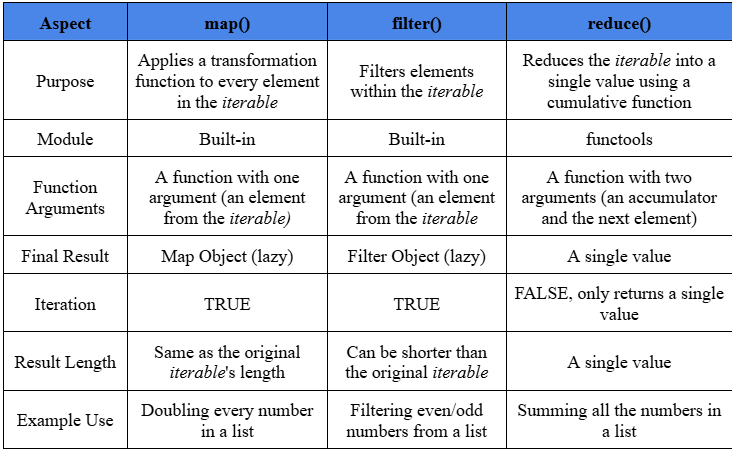

All three are concrete proof that functions are first-class citizens in Python: each one *accepts a function as input*, exactly like our `calculate` example above. We will use plain **named functions** (defined with `def`, no `lambda`) as the "logic" we hand to them, so the code stays explicit and easy to trace.

We only touch on their signatures and mechanism here. The full implementation with step-by-step examples on numeric data, dictionaries, strings, and nested lists, is covered in detail in **Section 3: Data Processing Techniques in  Functional Paradigm**, right after we look at why immutability matters for this kind of data transformation.

Let's see all three **in action** with one minimal example each, just so the concept is concrete before we go further. We use a small list of numbers and three simple named functions:

In [ ]:
numbers = [1, 2, 3, 4, 5]

# a one-argument function: doubles a value
def double(x):
    return x * 2

# a one-argument function: True when x is even
def is_even(x):
    return x % 2 == 0

# a two-argument function: adds two values
def add(a, b):
    return a + b

In [21]:
from functools import reduce

print(list(map(double, numbers)))     # map    -> transform every element
print(list(filter(is_even, numbers))) # filter -> keep only the elements that pass
print(reduce(add, numbers))           # reduce -> fold every element into one value

[2, 4, 6, 8, 10]
[2, 4]
15


Three lines, three different jobs:
- `map(double, numbers)` hands **every** element to `double`, so we get a new sequence `[2, 4, 6, 8, 10]`.
- `filter(is_even, numbers)` hands every element to `is_even`; only the ones where it returns `True` survive, giving `[2, 4]`.
- `reduce(add, numbers)` keeps folding pairs together with `add` — `(((1+2)+3)+4)+5` — until a single value, `15`, is left.

In each case, *we* supply the small named function (`double`, `is_even`, `add`); `map`/`filter`/`reduce` supply the looping. That hand-off is exactly what makes them Higher-Order Functions. This is only a quick preview to make the idea concrete — the full implementation, including *lazy evaluation*, dictionaries, strings, nested lists, and the `reduce` initializer, is covered in depth in **Section 3**.

### How each one actually works, step by step

`map(double, numbers)` walks through `numbers` **one element at a time** and calls `double` on each:
1. `double(1)` → 2
2. `double(2)` → 4
3. `double(3)` → 6
4. `double(4)` → 8
5. `double(5)` → 10

Result: a new sequence `[2, 4, 6, 8, 10]` — **same length** as the input, values transformed.

`filter(is_even, numbers)` also visits every element, but instead of transforming it, it asks `is_even` a yes/no question and keeps only the elements answered `True`:
1. `is_even(1)` → `False` → dropped
2. `is_even(2)` → `True` → kept
3. `is_even(3)` → `False` → dropped
4. `is_even(4)` → `True` → kept
5. `is_even(5)` → `False` → dropped

Result: `[2, 4]` — **same or fewer** elements, values themselves untouched.

`reduce(add, numbers)` is different again — it doesn't build a sequence at all. It carries an **accumulator** forward, combining two values at a time until only one is left:
1. `add(1, 2)` → 3
2. `add(3, 3)` → 6
3. `add(6, 4)` → 10
4. `add(10, 5)` → 15

Result: a **single value**, `15`.


Notice the pattern in the function signatures themselves: `map` and `filter` both take a **one-argument** function and hand back a sequence, while `reduce` takes a **two-argument** function and hands back one value. That difference isn't an accident — it comes directly from what each one is built to do: *transform-each* (`map`), *keep-some* (`filter`), or *fold-to-one* (`reduce`).

```
📌 Exercise 4: The Truthy Trap
```
Above, `is_even(x)` returns `x % 2 == 0`, so `filter(is_even, numbers)` keeps values where the result is True. Now write a second version that returns `x % 2` instead,  run it through `filter()` the same way.


In [22]:
#202410370110424

def is_odd(x):
    return x % 2

print(list(filter(is_even, numbers)))
print(list(filter(is_odd, numbers)))

[2, 4]
[1, 3, 5]


```
 📝 Analysis Question
```
Compare the two results. Did `filter()` behave the same way with both? What does this tell you about what `filter()` actually requires from the function it's given — does it need an actual boolean, or just something Python considers truthy/falsy?

# **3. Data Processing Techniques in Functional Paradigm**

In the functional paradigm, programs are structured as pipelines that transform data from one state to another. Let's look at a few real-world examples of how this functional paradigm works in our field (informatics):

1. For **back-end** server programming, we can model it as a process that transforms an HTTP request into an HTTP response.
2. For **front-end** programming, we can model it as a process that transforms data from the server into a UI representation.
3. A **compiler** is a program that transforms source code into an executable.



<p align="justify"> Data transformation relies on <b>immutability</b>: once created, data is not changed. Every function returns a <i>new</i> value instead of mutating the original, so data stays predictable and can only change through our transformation functions. We met this in Module 2 as the <i>pure function</i> requirement. This is the third trait of the functional paradigm: <b>transform data, use immutability, never mutate</b>.

When we work with data collections (range, list, tuple, dictionary, …) two patterns are very common:

1. **Iterate to build another collection** — transform or test each item and add the result to a new collection (the idea behind `map()` and `filter()`).
2. **Iterate and accumulate into a single value** — e.g. `len()`, `min()`, `max()`, `sum()`, and `reduce()`.

In practice, we avoid writing imperative `for`/`while` loops for these two patterns and instead rely on Python's built-in Higher-Order Functions `filter()`, `map()`, and `reduce()`, whose signatures we already met in Section 2.

Combined with **immutability** and **lazy evaluation**, they let us express *what* transformation we want instead of *how* to loop through it step by step — keeping the code concise, declarative, and free of side effects.

Let's look at each of the three in detail, complete with real-world cases.

## 3.1 Filter

List comprehension with an `if` also filters, but it computes everything at once (*eager evaluation*). Python's `filter()` is more efficient because it is **lazy**, data is processed only when needed.

`filter` takes two arguments-`(function, iterable)`:
1. **A logic function** → returns `True`/`False` for each element.
2. **An iterable** → the data to filter.

It runs the logic function on every element; `True` keeps the element, `False` drops it. The result is a *filter object* that is only evaluated when needed. More detail: [geeksforgeeks](https://www.geeksforgeeks.org/python/filter-in-python/) or [realpython](https://realpython.com/python-filter-function/).

### Example 1: Filtering numeric data

In [68]:
# first, prepare a logic function
def passed(score):
  ''' function to check whether a score passes
      pre-cond: score is a number
      post-cond: Boolean value; True if score >= 70
  '''
  return score >= 70

# Student score data
scores = [55, 80, 72, 65, 90, 45, 88, 60, 90, 50, 73]

In [ ]:
# using filter
passing_scores = filter(passed, scores)

print(passing_scores)

The result above is a *filter object* because it is *lazy*. To see its contents, we can access it with `next()`, using a `for` loop, or by directly converting it into another data type (list/tuple) using casting.

In [ ]:
# Accessing the filter result above with next()
print('First item:', next(passing_scores))
print('Second item:', next(passing_scores))

# Accessing the remaining items with a loop
print('The rest:')
for item in passing_scores:
    print(item, end=", ")

First item: 80
Second item: 72
The rest:
90, 88, 90, 73, 

converted into tuple data:

In [ ]:
# the filter object needs to be recreated
# because its elements have already been exhausted from the previous iteration
passing_scores = filter(passed, scores)
list(passing_scores)

[80, 72, 90, 88, 90, 73]

### Example 2: Filtering dictionary data (students)

In [ ]:
students = [
    {"name": "Dika", "score": 100},
    {"name": "Wira", "score": 55},
    {"name": "Fatih", "score": 85},
    {"name": "Alif", "score": 45},
    {"name": "Ega", "score": 90}
]

# logic function for student data
'''
 function to check whether a student passes based on their score
 pre-cond: score is a dictionary that has a "score" key inside it
 post-cond: True value if score >= 70
'''
def student_passed(score):
    return score["score"] >= 70

In [ ]:
passing_students = filter(student_passed, students)
print(passing_students) #lazy

In [ ]:
print(tuple(passing_students)) #directly cast to a tuple type

({'name': 'Dika', 'score': 100}, {'name': 'Fatih', 'score': 85}, {'name': 'Ega', 'score': 90})


```
📌 Exercise 5: The Empty Shelf
```

Given the product data below, complete the code puzzle in the next cell to keep only the products whose `stock` is **empty (0)**.

In [47]:
products = [
    {"name": "Laptop", "stock": 3},
    {"name": "Mouse", "stock": 0},
    {"name": "Keyboard", "stock": 8},
    {"name": "Monitor", "stock": 0},
    {"name": "Flashdisk", "stock": 10}
]

Fill in the blanks (`____`) in the code cell below. You need:
1. A logic function that checks whether a product's stock is zero,
2. A `filter()` call that uses it,
3. For odd NIM, cast the `out_of_stock` data into a tuple; for even NIM, cast it into a list.

In [ ]:
# 202410370110424

def is_out_of_stock(product):
    """Return True when this product's stock is 0."""
    return product["stock"] == 0

out_of_stock = filter(is_out_of_stock, products)
print(list(out_of_stock))


[{'name': 'Mouse', 'stock': 0}, {'name': 'Monitor', 'stock': 0}]



```
📝 Analysis Question
```
Your `filter()` result `out_of_stock` is a *lazy* object. What happens if you iterate over it with a `for` loop ? what do you get, and why does that happen?

In [58]:
#202410370110424
for product in out_of_stock:
    print(product)

## 3.2 Map

### Example 1: Mapping numeric scores into letter grades

In [69]:
# make sure the filter code cell has already been run
# Transformation function to be used inside the map() function
'''
 function to transform a score value into a letter grade
 pre-cond: score is a number
 post-cond: a letter grade of 'A', 'B', or 'C'
'''
def to_grade(score):
    if score >= 85:
        return "A"
    elif score >= 70:
        return "B"
    else:
        return "C"

In [70]:
#using map
grades = map(to_grade, scores)
print(scores)
print(grades)          # only displays the object (because it's lazy)
print(list(grades))    # cast/convert to a list to print all the results

[55, 80, 72, 65, 90, 45, 88, 60, 90, 50, 73]
['C', 'B', 'B', 'C', 'A', 'C', 'A', 'C', 'A', 'C', 'B']


Just like `filter()`, the result of `map()` is also **lazy**. Printed directly, it only shows the map object; to see its contents convert it to a list, use `next()`, or iterate with a loop.



```
📌 Exercise 6: The Vanishing Iterator
```

Before you run the cell below, trace through it **by hand**: for each iteration of the loop, write down what `score` is and what value `next(grades)` should produce. Then run it and check your trace.

PS: `scores` are from example 1 in filter section

In [ ]:

#202410370110424
grades = map(to_grade, scores)

print("Scores with Grades:")
# iterate to display the grades data using next()
for score in scores:
    print(score,'=',next(grades))

# Exercise 5 attempt — add your hand-trace as comments here, e.g.:
# score=55 -> next(grades) should be 'C'
# score=80 -> next(grades) should be 'B'
# ...


Scores with Grades:
55 = C
80 = B
72 = B
65 = C
90 = A
45 = C
88 = A
60 = C
90 = A
50 = C
73 = B


```
📝 Analysis Question
```
The loop above says `for score in scores`, **not** `for score in grades`, even though we are printing grades. Why does iterating over `scores` while pulling values from `grades` with `next()` work correctly?
Is there a risk of a `StopIteration` error here?

### Example 2: Mapping on a String

What about non-numeric data such as a String? `map()` works on it too, as long as its two requirements are met: (1) a transformation function, and (2) sequence/iterable data. A string is a *sequence of characters*, so it can be a `map()` input. Let's prove it:

In [ ]:
#prepare a string transformation function
'''
desc: the uppercase(s) function converts the input string (s) into uppercase letters
pre-cond: input s must be of string type
post-cond: the input string is returned in uppercase form
'''
def uppercase(s):
  return s.upper()

In [ ]:
string = 'myname'
caps_name = map(uppercase,string)
print(list(caps_name))

['M', 'Y', 'N', 'A', 'M', 'E']


### Example 3: Mapping on a List of Strings

In [78]:
# List of strings
name_list = ['wendy', 'ian', 'ayu']

# Function to append an email format to a name
def add_email(name):
    return name + "@gmail.com"

emails = map(add_email, name_list)
print(list(emails))

['wendy@gmail.com', 'ian@gmail.com', 'ayu@gmail.com']


In [79]:
#using the uppercase() function on name_list
caps_name = map(uppercase,name_list)
print(list(caps_name))

NameError: name 'uppercase' is not defined

What happens if the `uppercase()` function is used on the `scores` data, which is numeric?

In [80]:
scores = [80, 75, 90]

caps_name = map(uppercase,scores)
print(list(caps_name)) #will error

NameError: name 'uppercase' is not defined

Huh, why does it error??

Because the `upper()` function can only be run on strings, not integers.
This error occurs because the input does not match the function's pre-condition — meaning, the `uppercase()` function expects string data, while what was given was a number.

### Example 4: Map on a Nested List

 After learning the basic concept of the `map()` function, which lets us apply a function to every element of a list efficiently, we can go further by applying it to a nested list.

 The `map()` function can also be used to apply a function to every element of a nested list in a functional way.




In [81]:
# Student score data per subject
student_scores = [
    [80, 75, 90],   # Student 1
    [60, 70, 65],   # Student 2
    [85, 88, 92]    # Student 3
]

# Function to add a +5 bonus to a score
def bonus(score):
    return score + 5

```
📌 Exercise 7: Mapping Over Rows
```
The code below first tries applying `bonus()` directly to the nested list `student_scores`, then applies it properly row by row using a list comprehension. Run the code below to check the output!

In [83]:
#202410370110424
list(map(bonus,student_scores))

TypeError: can only concatenate list (not "int") to list

In [76]:
# Apply map to each row (each student's scores)
bonus_scores = [list(map(bonus, row)) for row in student_scores]

print("original scores\t\t:", student_scores)
print("Total scores + bonus\t:", bonus_scores)

original scores		: [[80, 75, 90], [60, 70, 65], [85, 88, 92]]
Total scores + bonus	: [[85, 80, 95], [65, 75, 70], [90, 93, 97]]


```
📝 Analysis Question
```
Explain why `list(map(bonus, student_scores))` doesn't work as expected when applied directly to the nested list, and why looping over each row with a list comprehension before calling `map()` is necessary to get the correct result.

## 3.3 Reduce

![Python reduce Function](https://files.realpython.com/media/The-Python-reduce-Function-Guide_Watermarked.c2e2f64a48d2.jpg)


The `reduce()` function in Python is used to **reduce/fold** a collection of data down to just a **single value**. The difference from the previous two functions:
* `map()` transforms every element,
* `filter()` filters out some elements,
>while `reduce()` combines all elements until only one final result remains.

This function requires at least two arguments, namely:

1. **A two-argument function** (a function that accepts 2 inputs and produces 1 output)
2. **Iterable** (sequence data such as a list or tuple).

In addition, there is also an **initializer**, an optional third argument, which will be discussed later.

Example: A simple function for addition

In [ ]:
'''
desc: Function to add a and b
pre-cond: a and b can be any data
post-cond: a+b as the return value
'''
def add(a, b):
  result =  a + b
  return result

add(10, 7)

17

The `add()` function is suitable for use inside `reduce()` because it satisfies the requirement:
>accepts two arguments (`a` and `b`) then returns a single `result` value.

Before using the reduce function, we need to import the module/library where reduce is located. `reduce()` is not a direct Python built-in function, but resides inside the **functools** module. So before using it, we must perform an import from a `functools` library.

In [ ]:
from functools import reduce

### Experiment 1: Reduce on a list of numbers

In [ ]:
scores = [50, 70, 90]

# Calculate the total score with reduce
total = reduce(add, scores)
print("Total score:", total)

Total score: 210


The process above is the same as running the operation `((50 + 70) + 90) = 210`. So reduce folds the elements step by step until only one value remains.

`reduce()` also accepts an optional **third argument**, the **initializer** — the starting point of the reduction. Without it, reduce starts from the first two elements; with it, reduce starts from the initializer and the first element (as if an extra element were placed at the front). Example:

In [ ]:
#adding the value 100 as the initializer/3rd argument of reduce
total_bonus = reduce(add, scores, 100)
print("Total score with bonus:", total_bonus)

Total score with bonus: 310


The values `[50, 70, 90]` are added starting from `100`:

1. 100 + 50 = 150
2. 150 + 70 = 220
3. 220 + 90 = 310

Final result: `310`. An initializer is handy for a starting value — bonus points, an initial balance, an offset, or another default counted from the start.

### Experiment 2: Reduce on map results

In [ ]:
caps_string = map(uppercase,string)
list(caps_string)

['M', 'Y', 'N', 'A', 'M', 'E']

How do we combine the mapped characters back into one string? Use `reduce()` with `add()` to fold them together. Note: `+` inside `add()` also works on strings (as concatenation) — recall its pre-condition that's allows any data. Let's prove it:

In [ ]:
caps_string = reduce(add,map(uppercase,string))
caps_string

'MYNAME'

### Experiment 3: Reduce on a Nested List

In [84]:
# the student_scores data is already available from the map-nested list material (Example 4)
print("Original data:", student_scores)

Original data: [[80, 75, 90], [60, 70, 65], [85, 88, 92]]


Now let's try folding this nested list with `reduce()`, the same way we did for a flat list of numbers. Since `student_scores` is a list of *lists* (one list per student), the elements `reduce()` iterates over are not individual numbers, but whole sub-lists. This changes what each call to `add(a, b)` actually receives, as we'll see in the exercise below.

```
📌 Exercise 8: Flatten & Sum
```

> Make sure you have run all the cells above (this exercise uses `student_scores` data and `add()` function).

**a.** The cell below is *broken* in the sense that it doesn't do what a beginner might expect. Run it and observe the result before reading further.

In [85]:
reduce1 = reduce(add, student_scores)
# 202410370110424
# Exercise 8a

**b.** Now fix it: write code that adds up **every single number** inside `student_scores` into one grand total. (Hint: apply `reduce` twice — once per row, then once across the row totals.)



In [ ]:
# 202410370110424
# Exercise 8b

def sum_row(row):
    return reduce(add, row)

row_totals = list(map(sum_row, student_scores))
grand_total = reduce(add, row_totals)

print("Total seluruh nilai:", grand_total)

Total seluruh nilai: 705


```
📝 Analysis Question
```
Why did the plain `reduce(add, student_scores)` in part (a) **not** collapse into one number the way it did for a flat list of numbers? Looking at what `add(a, b)` actually received on its first call, what does this reveal about how `reduce` treats each *element* of the iterable it's given — does it "see" the numbers inside a sub-list, or just the sub-list itself?

And explain how your answer in part (b) gets the job done!

## 3.4. Recursive Functions

You have seen how `map()`, `filter()`, and `reduce()` allow us to transform, select, and aggregate sequences without writing manual for or while loops. These tools abstract away iteration by focusing on what should happen to each element rather than how to step through indices.

However, a fundamental question remains:
>how do we perform repetition when built-in sequence abstractions aren't enough, or when processing custom data structures?

In imperative programming, you rely on mutable loop counters (`i += 1`) and state updating in place. In pure functional programming, repetition is expressed through **recursion**:
>decomposing a problem into smaller instances of itself until a base case is reached.

In fact, map, filter, and reduce are not magic—under the hood, functional environments often define those exact data-processing abstractions using pure recursive logic.

A **recursive function** calls itself during its execution. It suits problems that break into smaller sub-problems of the same shape (*factorial, Fibonacci, geometric series*, …), often giving shorter, clearer code than a loop.

**Basic example: factorial.** The factorial of *n* is the product of all integers from 1 to *n*,

e.g. 5! = 5 × 4 × 3 × 2 × 1 = 120.

In [93]:
'''
desc: function to recursively calculate the factorial of a number n
pre-cond: input n is an integer >= 0
post-cond: the factorial value of n
'''
def recursive_factorial(n):
    if n <= 1:
        return 1  # Base Case
    else:
        return n * recursive_factorial(n - 1)  # Recursive Case

In [94]:
print(recursive_factorial(5))

120


How it works:
* factorial(5) → 5 × factorial(4)
* factorial(4) → 4 × factorial(3)
* factorial(3) → 3 × factorial(2)
* factorial(2) → 2 × factorial(1)
* factorial(1) → 1 (base case — recursion stops and return)

So the process is 1 × 2 × 3 × 4 × 5 = 120, the value returned and printed.

A recursive function has two parts:

1. ***Base Case*** — the condition that stops the recursion. Without it, the function calls itself endlessly and causes a *stack overflow*.
2. ***Recursive Case*** — the part that calls itself on a smaller sub-problem until it reaches the base case.

**Think of recursion as the foundation of `reduce`**: at every step, you take the current element, process it, and pass the running result down the line. The difference: `reduce` calls another function, while recursion calls itself.

The earlier factorial can also be written with `reduce`:

In [95]:
def multiply(a, b):
    return a * b

print(reduce(multiply, range(1, 6))) # multiplies every number in the range

120


**Another Example: Calculating Data Length**

Besides factorial, we can also use recursion to calculate the length of a piece of data. Even though Python already provides the `len()` function, this recursive version is useful for understanding the concept of recursion more deeply.

In [96]:
# let's use the data from the result of Experiment 2 in the reduce material, namely:
caps_string

NameError: name 'caps_string' is not defined

In [92]:
# without recursion
def count_loop(data):
    count = 0
    for char in data:
        count += 1
    return count

print("Length of data",caps_string,'=', count_loop(caps_string))


NameError: name 'caps_string' is not defined

In [89]:
# using recursion
def count_recursive(data):
    if data == '': # Base Case: if the string is empty
        return 0
    else:  # Recursive Case: 1 + count_recursive(data--starting from index 1)
        return 1 + count_recursive(data[1:]) #excluding the element at index 0

print("String length (recursive):", count_recursive(caps_string))  #Output: 6


NameError: name 'caps_string' is not defined

**Decomposing Data: Head and Tail**

Processing a sequence recursively relies on a simple pattern: splitting a sequence into its head (the first element) and its tail (all remaining elements).


```
data = 'MYNAME'

head = data[0]  #'M'
tail = data[1:] #'YNAME'
```



Recursion fits the functional paradigm because it replaces imperative loops (`for`/`while`) and avoids side effects such as a constantly changing counter. It naturally suits problems that split into smaller, similar sub-problems — like counting a string: take one character, then count the rest the same way, repeatedly.
>Isn't this the simple way we teach children to count a collection of objects...

```
📌 Exercise 9: Think Recursively
```
**a.** Complete the recursive function `sum_list(data)` below so it adds all the numbers in a **flat** list, **without** using `sum()`, `reduce()`, or a loop. Identify your base case and recursive case in comments.

**b.** Use it to total the flattened `student_scores`, and check that your recursive answer matches the `reduce` answer from Exercise 8b.

In [102]:
#202410370110424
def sum_list(data):
    # base case: empty list -> 0
    if len(data) == 0:
            return 0
    # recursive case: first element/head + sum_list(the rest/tail)
    return data[0] + sum_list(data[1:])
flat_scores = [score for row in student_scores for score in row]
print(sum_list(flat_scores))

705


```
📝 Analysis Question
```
Both reduce and recursion process sequences incrementally, carrying accumulated results from one step to the next. In your `sum_list`, which part plays the same role as `reduce`'s accumulator?

Point out your base case explicitly, and explain why the function would never terminate without it. Finally, give one situation where recursion reads more clearly than `reduce`, and one situation where `reduce` is the better choice.

# **CODE ANALYSIS**

The Code Analysis assignment consists of Exercises (1 to 9) and Analysis Questions. Complete the exercises in Google Colab, and write your answers in the provided [Report Template](https://docs.google.com/document/d/1YOJg0bupDQ-SURynwgK8mj84MsYaNr5w/edit?usp=drive_link&ouid=113070955082578078630&rtpof=true&sd=true)

**Verification & Deadline**

- You **must** have submitted your report on iLab/MiLab in PDF format before the practicum session for that module begins, so that the assistant can grade it or request revisions.
- You **must show** your Exercise work on the running Notebook, and modify the exercises according to the instructions given by the assistant.
- If you do not show the exercise and report to the assistant, you must still **submit the report** to iLab/miLab in PDF format no later than **1 day after the practicum session (H+1)**. However, **the Practicum Report score will be -40 points, and the Exercise Implementation score will be 0**.
- If the assistant gives revisions, whether on the Exercise or the Explanation Report, you **must complete those revisions during the practicum session**. Revisions submitted H+1 or via iLab will not be accepted.


# **ASSIGNMENT**

## ASSIGNMENT 1

You work at a hotel and are given the following room booking data:

In [ ]:
bookings = [
    {"booking_code": "B001", "nights": 3, "price_per_night": 250000, "status": "Confirmed"},
    {"booking_code": "B002", "nights": 2, "price_per_night": 300000, "status": "Pending"},
    {"booking_code": "B003", "nights": 5, "price_per_night": 220000, "status": "Confirmed"},
    {"booking_code": "B004", "nights": 1, "price_per_night": 450000, "status": "Confirmed"},
    {"booking_code": "B005", "nights": 4, "price_per_night": 180000, "status": "Cancelled"},
    {"booking_code": "B006", "nights": 2, "price_per_night": 275000, "status": "Pending"},
    {"booking_code": "B007", "nights": 6, "price_per_night": 200000, "status": "Confirmed"},
    {"booking_code": "B008", "nights": 3, "price_per_night": 320000, "status": "Confirmed"},
    {"booking_code": "B009", "nights": 2, "price_per_night": 260000, "status": "Cancelled"},
    {"booking_code": "B010", "nights": 7, "price_per_night": 190000, "status": "Confirmed"},
    {"booking_code": "B011", "nights": 1, "price_per_night": 400000, "status": "Pending"},
    {"booking_code": "B012", "nights": 4, "price_per_night": 230000, "status": "Confirmed"},
    {"booking_code": "B013", "nights": 5, "price_per_night": 210000, "status": "Confirmed"},
    {"booking_code": "B014", "nights": 2, "price_per_night": 500000, "status": "Cancelled"},
    {"booking_code": "B015", "nights": 3, "price_per_night": 240000, "status": "Confirmed"}
]


Next, you are asked to build a small **Hotel Booking Revenue System** using the `bookings` data above. This task pulls together **everything from this module**. Lambda is **not allowed**; every function must be named and pure so that does not mutate the original `bookings` list.


Complete the four parts below in order. Each section specifies what the functions should do, leaving the implementation (how) to you. Run each cell before moving on, as later tasks depend on earlier definitions.

### Part 1
1. Write three functions of pricing strategy:
- `standard_price` which returns the total cost of a stay;
- `discount_price` which returns the total cost of a stay with a 15% discount;
- `tax_price` which returns the total cost of a stay including a 10% tax.
2. Complete `apply_pricing()` as a Higher-Order Function that accepts a function as a parameter and returns a new function which, when applied to a single booking data, produces a new booking dictionary — identical to the original plus one extra key, `"total_cost"`, worked out by calling `strategy` on that booking's own numbers.
3. Pass your chosen pricing strategy function into the Higher-Order Function and store the returned function in a variable named `pricing_strategy`. We'll use this as the transformation argument inside `map()` later


In [ ]:
# 1
def standard_price(nights, price_per_night):
    ____
# also define the other pricing strategies: discount and tax

# 2
def apply_pricing(strategy):
    def add_total(booking):
        ____

    return ____

# 3
pricing_strategy = ____

### Part 2
Three logic functions are needed for the next parts, each ready to be handed to `filter()`:

- `is_eligible(booking)` → `True` only if the booking qualifies for a loyalty discount: it stayed **at least 3 nights**, **and** its status is `"Confirmed"` — both conditions at once.
- `is_confirmed(booking)` → `True` only if the booking's status is `"Confirmed"` (needed later to isolate real revenue).
- `is_not_cancelled(booking)` → `True` for any booking whose status is **not** `"Cancelled"` (needed later so cancelled stays don't count toward total nights).

`is_not_cancelled` is already provided in both blocks below.
Complete `is_eligible` and `is_confirmed`

In [ ]:
def is_not_cancelled(booking):
    return booking["status"] != "Cancelled"

def is_eligible(booking):
    ____

def is_confirmed(booking):
    ____

### Part 3
1. Create a clean `add` function that takes two numeric values and returns their total. We will use this as the driving function for `reduce()` to calculate aggregate totals across our dataset.

2. Then write a **recursive** function (without loop or `sum()`) that adds up the `required` (can be night or price) field across a list of `datas`. Think carefully about what should happen when `datas` is empty (your base case), versus when it still has `datas` left (your recursive case).

In [ ]:
# 1
def add(a, b):
    ____

# 2
def totals(datas, required):
    if ____:
        return ____
    return ____

### Part 4
Now that all the functions needed are  ready, put them to work together in one pipeline. Using the functions you built in Part 1–3, you'll compose them to answer real business questions about the bookings — enriching data, grouping by eligibility, calculating totals, etc. — all without mutating the original bookings list.

This part is done live during your demo session, where your assistant will give you 2 scenarios, each requiring you to compose the functions from Part 1–3 in a different way. As a reference for how the pipeline is meant to be used, here's how the scenario "total nights from non-cancelled bookings" is implemented:

In [ ]:
not_cancelled = list(filter(is_not_cancelled, bookings))
total_nights_result = totals(not_cancelled, 'nights')

print("Total nights from non-cancelled bookings")
print(total_nights_result)

Total nights from non-cancelled bookings
42


Be ready to apply the similars pattern — calling the right function(s) from Part 1–3 and composing them with `map`/`filter`/`reduce`.

In [ ]:
#finally:
# check the original bookings data [must not change]
bookings

## ASSIGNMENT 2

Continuing the project from Modules 1 and 2, you are now asked to develop your program by implementing the concepts learned in this module: **First-Class Functions**, **Higher-Order Functions**, sequence data processing techniques (`map()`, `filter()`, `reduce()`), and **recursion**.

Assignment Requirements

1. Add a new feature or modify an existing one. Your implementation must make use of the First-Class Function concept (e.g. higher-order functions) and Recursion.
2. At least 2 data processing techniques implemented, either: `map()`, `filter()`, or `reduce()`.
3. Briefly explain the reason for using the chosen concept or function (for example: why you used `filter()` to process certain data, or why you designed a function to accept another function as a parameter).


# Assessment Rubric

| Assessment Aspect | Points (Total 100%) |
| :--- | :---: |
| **Code Analysis** | **20** |
| - Exercise Implementation | 10 |
| - Practicum Report | 10 |
| **Assignment 1** | **40** |
| - Code / Feature Completeness | 10 |
| - Code Correctness & Accuracy (Live Code)| 15 |
| - Understanding | 15|
| **Assignment 2** | **40** |
| - First-Class Function Features  | 15 |
| - Concept Implementation in Data Transformation| 10 |
| - Understanding | 15|


| Activity                               |            Time |
| -------------------------------------- | --------------: |
| **Assignment 1 - Live Coding**         |  **10 minutes** |



## DETAILED ASSESSMENT RUBRIC

**ASSIGNMENT 1 (Total 40%)**

| Aspect | Points | Score | Criteria |
| --- | ---: | ---: | --- |
| **Code / Feature Completeness** | **10** | **100** | All features implemented correctly (Parts 1–3 without lambdas or state mutation). |
|  |  | **80** |  All features Implemented, with minor logic or formatting errors. |
|  |  | **60** | Only 2 features are correctly implemented and the other feature does not follow most requirements. |
|  |  | **40** | Only 1 features are correctly implemented and the other feature does not follow most requirements. |
|  |  | **0** | Fails to implement core functional operations or violating assignment constraints.|
| **Code Correctness & Accuracy (Live Code)** | **15** | **100** | Both live scenarios were completed correctly. |
|  |  | **80** | Both completed with minor bugs in one. |
|  |  | **60** | Only 1 of 2 scenarios is correct. |
|  |  | **40** | Attempted but code errors / doesn't run. |
|  |  | **0** | Does not do anything. |
| **Understanding** | **15** | **100** | Clearly explains how first-class functions(1), higher-order functions(2), map/filter/reduce(4), and recursion(4) are implemented throughout the pipeline. |
|  |  | **80** | Can explain most concepts (at least 3), but one concept is not discussed in sufficient depth. |
|  |  | **60** | Understands the general idea, but the explanation lacks details. |
|  |  | **40** | Has difficulty explaining most of the code and concepts. |
|  |  | **0** | Cannot explain the implementation or the concepts at all. |

------



**ASSIGNMENT 2 (Total 40%)**

| Aspect | Points | Score | Criteria |
| --- | ---: | ---: | --- |
| **First-Class Function Features** | **15** | **100** | Correctly implements Higher-Order Function and Recursion. |
|  |  | **80** | Implemented both and mostly correct, but with minor logic/formatting errors. |
|  |  | **60** | Only 1 feature is correctly implemented and the other feature does not follow most requirements. |
|  |  | **40** | Partial implementation of one or both features, with superficial functionality or recurring errors. |
|  |  | **0** | No implementation of the Higher-Order Function and Recursion. |
| **Concept Implementation in Data Transformation** | **10** | **100** | Correctly implements at least two of `map()`/`filter()`/`reduce()`, without mutating original data. |
|  |  | **80** | Applied, mostly correct, with minor logic/formatting errors. |
|  |  | **60** | Only one Applied or significant logic errors/incomplete integration into the pipeline. |
|  |  | **40** | Attempted but fails to run or produces incorrect output. |
|  |  | **0** | No use of map(), filter(), or reduce() at all. |
| **Understanding** | **15** | **100** | Can clearly explain why the chosen concepts were used, tied directly to the implementation. |
|  |  | **80** | Can explain most concepts, but one concept is not discussed in sufficient depth. |
|  |  | **60** | Only able to explain part of the concepts. |
|  |  | **40** | Has difficulty explaining most of the concepts. |
|  |  | **0** | Cannot explain the concepts at all. |